### Notebook 6e — Second Case Study: Other Classifier Architectures (Tuberculosis)

> Repeats the tuberculosis experiments of Notebook 6c with a **different classifier architecture** (ResNet-50 or ConvNeXt-Tiny, both pre-trained on ImageNet), to check whether the conclusions about the synthetic images depend on the classifier. The synthetic images, the scenarios, the seeds, the training protocol and the test sets are the same; only the network changes. Set `BACKBONE` and run one session per architecture.

**Inputs to attach** (three notebook outputs): **6a** (real images), **6b-1** (DC-GAN images) and **6b-2** (RoentGen images). Turn on a **GPU** and **Internet** (the ImageNet weights are downloaded from PyTorch).

**Scenarios** (`RUN` selects which ones are trained in this session; *N* = 600 synthetic images per class)

| Name | Training set |
|---|---|
| `T1` | Real Shenzhen training set (396 images, 201 tuberculosis): **baseline** |
| `T2` | DC-GAN only: *N* tuberculosis + *N* normal |
| `T3` | Real + *N* DC-GAN tuberculosis |
| `T4` | RoentGen-v2 only: *N* tuberculosis + *N* normal |
| `T5` | Real + *N* RoentGen-v2 tuberculosis |
| `T3-bal`, `T5-bal` | as `T3` / `T5` plus *N* synthetic normal images (removes "synthetic = tuberculosis" as a shortcut) |
| `T3-dose150`, `T3-dose300`, `T5-dose…` | as `T3` / `T5` with 150 or 300 synthetic tuberculosis images |

**Differences from Notebook 6c**: the network; images are replicated to 3 channels and normalised with the ImageNet mean/standard deviation inside the model, after the same rescaling used before; and the prediction files are named `<scenario>@<backbone>_seed<k>.csv.gz`.

**Differences from the pneumonia study**: there is no "more real data" scenario (the real set is the whole Shenzhen training set); the validation set has 100 images, so early stopping is noisier; and the RoentGen prompts that produced collages and lateral views are excluded (`ROENTGEN_EXCLUDE`, section 2).

**Same as before**: optimiser, augmentations, preprocessing, class-balanced sampler, training budget (at most 16 "epochs" of 150 batches), early stopping on the validation AUROC and the decision threshold (Youden index on the validation set). Nothing is selected on the test sets.

**Test sets**: `test` = 166 held-out Shenzhen images (same hospital as the training data) and `test_external` = 138 Montgomery images (a different hospital and scanner).

**Purpose**: a robustness check, not a model competition. Nothing is chosen on the test sets and no architecture is declared the winner; each architecture's scenarios are compared with *its own* real-only baseline `T1` (in Notebook 6d). The learning rates (1e-4 for ResNet-50, 5e-5 for ConvNeXt-Tiny) are standard fine-tuning values fixed beforehand and not tuned; the scenarios are the main ones of 6c (`T1`, `T2`, `T3`, `T5`).

**Saved** (`/kaggle/working`): `preds/<scenario>@<backbone>_seed<k>.csv.gz` (probabilities on `val`, `test`, `test_external` and on held-out synthetic normal images), `curves/…csv` and `runs_summary_<backbone>.csv`.

### 1. Configuration

In [1]:
import os, time, math, random, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')

# ---------------- what to run ----------------
BACKBONE = 'convnext_tiny'
RUN = ['T1', 'T2', 'T3', 'T5']                    # scenarios of Notebook 6c (same definitions)
SEEDS = [0, 1, 2]
SKIP_EXISTING = True                              # skip runs whose predictions are already saved (useful after a crash in an interactive session)

# ---------------- synthetic data ----------------
N_SYN = 600                                       # synthetic tuberculosis (and, in -bal and in T2/T4, normal) images per generator
N_NEG_TRAIN = 600                                 # synthetic normal images 0..599 can be used in training; 600+ are held out for the shortcut diagnostic
ROENTGEN_EXCLUDE = ['Bilateral upper lobe opacities.', 'Fibrocalcific changes in the upper lobes.']   # prompts that produced collages / lateral views (decided on the prompt test, not on any classifier)

# ---------------- model and training (identical for all scenarios) ----------------
LR_BY_BACKBONE = {'resnet50': 1e-4, 'convnext_tiny': 5e-5}      # fixed beforehand, not tuned
BATCH, STEPS_PER_EPOCH, MAX_EPOCHS, PATIENCE = 32, 150, 16, 4
LR, WD, WARMUP = LR_BY_BACKBONE[BACKBONE], 1e-4, 100
NORMALISE = True       # per-image percentile rescaling (1st-99th) applied to ALL images, real and synthetic, in training and test
RES_AUG   = True       # real training images are blurred to 128 px and back with probability 0.5; never applied to test images

# ---------------- paths ----------------
INPUT_ROOT, WORK = '/kaggle/input', Path('/kaggle/working')
for d in ('preds', 'curves'): (WORK / d).mkdir(exist_ok=True)

PRETRAINED = True                                # (set to False only for offline tests)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Enable a GPU accelerator (Settings -> Accelerator)'
print('GPU:', torch.cuda.get_device_name(0))
def set_seed(s): random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def find_dir(*names):
    for cur, dirs, files in os.walk(INPUT_ROOT):
        if all(n in files for n in names): return Path(cur)
    return None
CACHE_TB, CACHE_DC, CACHE_RG = find_dir('train.npy', 'val.npy', 'test_external.npy'), find_dir('dcgan.npy', 'dcgan_index.csv'), find_dir('roentgen.npy', 'roentgen_index.csv')
assert CACHE_TB, 'real images not found: attach the output of Notebook 6a'
assert CACHE_DC, 'DC-GAN images not found: attach the output of Notebook 6b-1'
assert CACHE_RG, 'RoentGen images not found: attach the output of Notebook 6b-2'
print('real     :', CACHE_TB); print('DC-GAN   :', CACHE_DC); print('RoentGen :', CACHE_RG)

GPU: Tesla T4
real     : /kaggle/input/notebooks/anamatemalas/06a-tb-data-preparation/cache_tb
DC-GAN   : /kaggle/input/notebooks/anamatemalas/06b1-dcgan-tuberculosis/cache_tb_syn
RoentGen : /kaggle/input/notebooks/anamatemalas/06b2-roentgen-tuberculosis/cache_tb_syn


### 2. Data

* **Real**: the Shenzhen `train` (396), `val` (100) and `test` (166) splits and the Montgomery `test_external` (138), all 224 × 224 `uint8`.
* **Synthetic**: DC-GAN and RoentGen images, 224 × 224. Within each class they are ordered by `rank` (the generation order); the first *k* are used for dose *k*. RoentGen tuberculosis images generated with the prompts in `ROENTGEN_EXCLUDE` are left out; the rank is computed after that exclusion.
* **Held-out synthetic normal images** (`rank` ≥ 600) are never used in training. They serve the shortcut diagnostic: if a model has learned "synthetic = tuberculosis", it scores them high.

In [2]:
ld = lambda d, nm: (np.load(d / f'{nm}.npy'), pd.read_csv(d / f'{nm}_index.csv'))
XTR, ITR = ld(CACHE_TB, 'train'); XV, IV = ld(CACHE_TB, 'val'); XT, IT = ld(CACHE_TB, 'test'); XE, IE = ld(CACHE_TB, 'test_external')
assert set(ITR['source']) | set(IV['source']) | set(IT['source']) == {'shenzhen'} and set(IE['source']) == {'montgomery'}
SYN = {}
for g, d in (('dcgan', CACHE_DC), ('roentgen', CACHE_RG)):
    X, I = ld(d, g); assert len(X) == len(I)
    keep = np.ones(len(I), bool)
    if g == 'roentgen': keep = ~((I.label == 1) & I['impression'].isin(ROENTGEN_EXCLUDE)).values
    X, I = X[keep], I[keep].reset_index(drop=True); I['rank'] = I.groupby('label').cumcount()
    assert (I.label == 1).sum() >= N_SYN and (I.label == 0).sum() > N_NEG_TRAIN, f'{g}: not enough synthetic images ({I.label.value_counts().to_dict()})'
    SYN[g] = (X, I)
print(f'real train {XTR.shape} (tuberculosis {int(ITR.label.sum())}) | val {XV.shape} (tuberculosis {int(IV.label.sum())}) | test {XT.shape} (tuberculosis {int(IT.label.sum())}) | external {XE.shape} (tuberculosis {int(IE.label.sum())})')
print(pd.DataFrame({g: {'tuberculosis available': int((I.label == 1).sum()), 'normal available': int((I.label == 0).sum()), 'held-out normal (rank >= %d)' % N_NEG_TRAIN: int(((I.label == 0) & (I['rank'] >= N_NEG_TRAIN)).sum())} for g, (X, I) in SYN.items()}).to_string())

SCENARIOS = {'T1': dict(real=True), 'T2': dict(syn='dcgan', n_pos=N_SYN, n_neg=N_SYN), 'T3': dict(real=True, syn='dcgan', n_pos=N_SYN),
             'T4': dict(syn='roentgen', n_pos=N_SYN, n_neg=N_SYN), 'T5': dict(real=True, syn='roentgen', n_pos=N_SYN)}
for g, s in (('dcgan', 'T3'), ('roentgen', 'T5')):
    for k in (150, 300): SCENARIOS[f'{s}-dose{k}'] = dict(real=True, syn=g, n_pos=k)
    SCENARIOS[f'{s}-bal'] = dict(real=True, syn=g, n_pos=N_SYN, n_neg=N_NEG_TRAIN)

def build_train(cfg):
    """Returns uint8 images, labels and a flag 'is synthetic' for one scenario."""
    xs, ys, sy = [], [], []
    if cfg.get('real'): xs.append(XTR); ys.append(ITR.label.values); sy.append(np.zeros(len(XTR), bool))
    if cfg.get('syn'):
        X, I = SYN[cfg['syn']]
        for lab, k in ((1, cfg.get('n_pos', 0)), (0, cfg.get('n_neg', 0))):
            m = ((I.label == lab) & (I['rank'] < k)).values
            if m.sum(): xs.append(X[m]); ys.append(I.label.values[m]); sy.append(np.ones(m.sum(), bool))
    return np.concatenate(xs), np.concatenate(ys).astype(np.float32), np.concatenate(sy)

for k, cfg in SCENARIOS.items():
    x, y, s = build_train(cfg)
    print(f'{k:12s} n={len(y):5d} | tuberculosis {int(y.sum()):4d} ({100 * s[y == 1].mean() if y.sum() else 0:3.0f}% synthetic) | normal {int((y == 0).sum()):4d} ({100 * s[y == 0].mean() if (y == 0).sum() else 0:3.0f}% synthetic)')
    del x

real train (396, 224, 224) (tuberculosis 201) | val (100, 224, 224) (tuberculosis 51) | test (166, 224, 224) (tuberculosis 84) | external (138, 224, 224) (tuberculosis 58)
                               dcgan  roentgen
tuberculosis available          1000       656
normal available                1000      1000
held-out normal (rank >= 600)    400       400
T1           n=  396 | tuberculosis  201 (  0% synthetic) | normal  195 (  0% synthetic)
T2           n= 1200 | tuberculosis  600 (100% synthetic) | normal  600 (100% synthetic)
T3           n=  996 | tuberculosis  801 ( 75% synthetic) | normal  195 (  0% synthetic)
T4           n= 1200 | tuberculosis  600 (100% synthetic) | normal  600 (100% synthetic)
T5           n=  996 | tuberculosis  801 ( 75% synthetic) | normal  195 (  0% synthetic)
T3-dose150   n=  546 | tuberculosis  351 ( 43% synthetic) | normal  195 (  0% synthetic)
T3-dose300   n=  696 | tuberculosis  501 ( 60% synthetic) | normal  195 (  0% synthetic)
T3-bal       n= 1

### 3. Preprocessing and Augmentation (on the GPU)

Unchanged from Notebook 4b.

* **Common to all images**: per-image rescaling between the 1st and 99th percentile of intensity (`NORMALISE`), then the XRV input range [-1024, 1024].
* **Training only**: random rotation (±10°), scale (±10%), translation (±5%), gamma (0.8-1.25) and, for real images only, a random 128-px blur (`RES_AUG`).
* Validation, test and the held-out synthetic images get only the common rescaling.

In [3]:
def rescale(x):                                                   # per-image percentile rescaling to [0, 1]
    f = x.flatten(1).float(); lo, hi = torch.quantile(f, 0.01, dim=1, keepdim=True), torch.quantile(f, 0.99, dim=1, keepdim=True)
    return ((f - lo) / (hi - lo + 1e-6)).clamp(0, 1).view_as(x)

def affine(x):
    B, dev = x.size(0), x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(10); sc = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.1
    tx, ty = (torch.rand(B, device=dev) * 2 - 1) * 0.1, (torch.rand(B, device=dev) * 2 - 1) * 0.1      # 5% of the width in [-1, 1] coordinates
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)
    return F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode='border', align_corners=False)

def degrade(x, is_syn):                                           # real images only: 224 -> 128 -> 224 with probability 0.5
    low = F.interpolate(F.interpolate(x, size=128, mode='bilinear', antialias=True, align_corners=False), size=x.shape[-1], mode='bilinear', align_corners=False)
    m = ((~is_syn) & (torch.rand(x.size(0), device=x.device) < 0.5)).view(-1, 1, 1, 1)
    return torch.where(m, low, x)

def prep(xb, is_syn=None, train=False):
    x = xb.to(DEVICE).float().div(255).unsqueeze(1)
    if train:
        if RES_AUG: x = degrade(x, is_syn.to(DEVICE))
        x = affine(x)
    if NORMALISE: x = rescale(x)
    if train: x = x.clamp(1e-4, 1) ** torch.empty(x.size(0), 1, 1, 1, device=DEVICE).uniform_(0.8, 1.25)
    return x * 2048 - 1024                                         # TorchXRayVision input range

### 4. Preprocessing Check

Can a simple detector (gradient boosting on pixel statistics) still tell real from synthetic images after the preprocessing? 5-fold cross-validated AUROC for each generator (0.5 = indistinguishable), on the images as they are, after the percentile rescaling, and with rescaling plus the 128-px blur of the real images. A pixel-statistics detector only; the result goes in the limitations section.

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

def pixel_stats(a):                                               # a: float32 (N, 224, 224) in [0, 1]
    x = a * 255; lap = np.abs(x[:, 1:-1, 1:-1] * 4 - x[:, :-2, 1:-1] - x[:, 2:, 1:-1] - x[:, 1:-1, :-2] - x[:, 1:-1, 2:]).mean((1, 2))
    fft = np.abs(np.fft.rfft2(x)); h, w = fft.shape[1:]; hf = fft[:, h // 4: 3 * h // 4, w // 4:].sum((1, 2)) / (fft.sum((1, 2)) + 1e-6)
    hist = np.stack([np.histogram(v, bins=16, range=(0, 255))[0] / v.size for v in x])
    return np.c_[x.mean((1, 2)), x.std((1, 2)), lap, hf, hist]

@torch.no_grad()
def to_float(u8, norm, blur):
    xb = torch.from_numpy(u8).float().div(255).unsqueeze(1)
    if blur: xb = F.interpolate(F.interpolate(xb, size=128, mode='bilinear', antialias=True, align_corners=False), size=224, mode='bilinear', align_corners=False)
    if norm: xb = torch.cat([rescale(xb[i:i + 64]) for i in range(0, len(xb), 64)])
    return xb.squeeze(1).numpy()

rs = np.random.RandomState(0); NCHK = 150; real_u8 = XTR[rs.choice(len(XTR), NCHK, replace=False)]; chk = []
for g, (X, I) in SYN.items():
    syn_u8 = X[rs.choice(len(X), NCHK, replace=False)]
    for name, norm, blur in [('raw', False, False), ('percentile rescaling', True, False), ('rescaling + 128-px blur of the real images', True, True)]:
        Xf = np.r_[pixel_stats(to_float(real_u8, norm, blur)), pixel_stats(to_float(syn_u8, norm, False))]; y = np.r_[np.zeros(NCHK), np.ones(NCHK)]
        p = cross_val_predict(HistGradientBoostingClassifier(random_state=0), Xf, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')[:, 1]
        chk.append({'generator': g, 'preprocessing': name, 'AUROC_real_vs_synthetic': roc_auc_score(y, p)})
chk = pd.DataFrame(chk); chk.to_csv(WORK / 'preprocessing_check.csv', index=False); print(chk.round(3).to_string(index=False))

generator                              preprocessing  AUROC_real_vs_synthetic
    dcgan                                        raw                    1.000
    dcgan                       percentile rescaling                    1.000
    dcgan rescaling + 128-px blur of the real images                    0.997
 roentgen                                        raw                    0.999
 roentgen                       percentile rescaling                    0.996
 roentgen rescaling + 128-px blur of the real images                    1.000


### 5. Visual Check of a Training Batch

Four real and four RoentGen tuberculosis images, as seen by the network at evaluation (top) and in training (bottom).

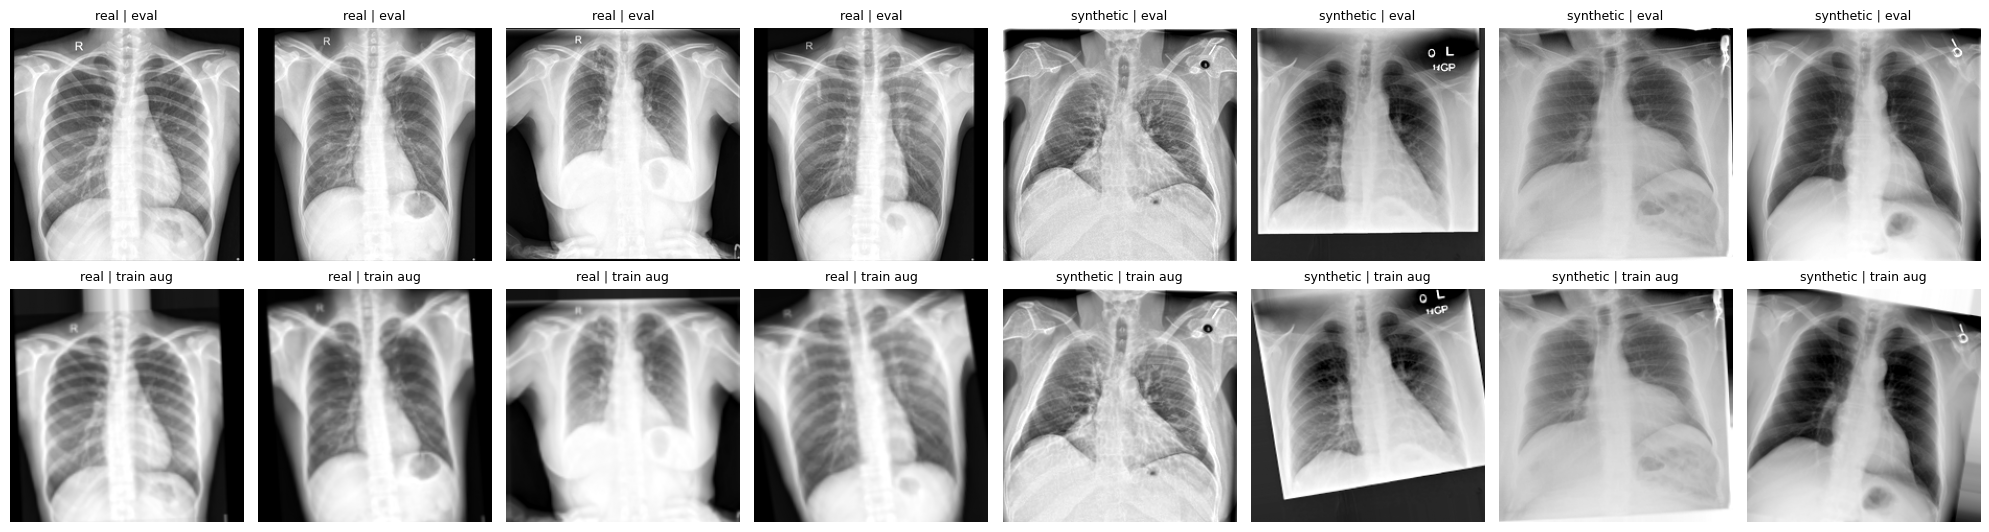

In [5]:
x, y, s = build_train(SCENARIOS['T5']); rs = np.random.RandomState(1)
ip = rs.choice(np.where((y == 1) & s)[0], 4, replace=False); ir = rs.choice(np.where((y == 1) & ~s)[0], 4, replace=False); idx = np.r_[ir, ip]
xb = torch.from_numpy(x[idx]); isb = torch.from_numpy(s[idx])
with torch.no_grad(): a, b = prep(xb, isb, train=False), prep(xb, isb, train=True)
fig, ax = plt.subplots(2, 8, figsize=(20, 5.5))
for k in range(8):
    for r_, t in enumerate((a, b)):
        ax[r_, k].imshow(t[k, 0].cpu(), cmap='gray'); ax[r_, k].axis('off'); ax[r_, k].set_title(('synthetic' if isb[k] else 'real') + (' | train aug' if r_ else ' | eval'), fontsize=9)
plt.tight_layout(); plt.show(); del x

### 6. Model, Training and Evaluation Functions

ImageNet-pre-trained ResNet-50 (2,048-d pooled features) or ConvNeXt-Tiny (768-d) from torchvision, with a new single-logit head (dropout 0.2). The 1-channel input in [-1024, 1024] is mapped back to [0, 1], replicated to 3 channels and normalised with the ImageNet statistics. Balanced sampler: every batch is drawn with equal probability for the two classes. Early stopping on the AUROC of the Shenzhen validation set (100 images, so a noisy criterion).

In [6]:
import torchvision
from torchvision import models as tvm
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        if BACKBONE == 'resnet50':
            m = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V1 if PRETRAINED else None); d = m.fc.in_features; m.fc = nn.Identity()
        elif BACKBONE == 'convnext_tiny':
            m = tvm.convnext_tiny(weights=tvm.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if PRETRAINED else None); d = m.classifier[2].in_features; m.classifier = nn.Sequential(m.classifier[0], m.classifier[1])
        else: raise ValueError(BACKBONE)
        self.base = m; self.drop = nn.Dropout(0.2); self.fc = nn.Linear(d, 1)
    def forward(self, x):
        x = ((x + 1024) / 2048).clamp(0, 1).expand(-1, 3, -1, -1); x = (x - MEAN) / STD
        return self.fc(self.drop(self.base(x))).squeeze(1)

@torch.no_grad()
def predict(model, X, bs=128):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = prep(torch.from_numpy(X[i:i + bs]))
        with torch.autocast('cuda', dtype=torch.float16): out.append(torch.sigmoid(model(xb).float()).cpu())
    return torch.cat(out).numpy()

def youden(y, p):                                                 # threshold maximising sensitivity + specificity - 1
    ts = np.unique(np.quantile(p, np.linspace(0, 1, 2001))); P, N = (y == 1).sum(), (y == 0).sum()
    j = [((p >= t) & (y == 1)).sum() / P + ((p < t) & (y == 0)).sum() / N - 1 for t in ts]; return float(ts[int(np.argmax(j))])

def fit(model, X, y, syn, seed, lr, tag):
    """Trains `model` on (X, y); returns the model with the best-validation weights loaded."""
    yt, st = torch.from_numpy(y), torch.from_numpy(syn)
    w = np.where(y == 1, 0.5 / (y == 1).sum(), 0.5 / (y == 0).sum()); w = torch.from_numpy(w).float()      # class-balanced sampling weights
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WD); scaler = torch.cuda.amp.GradScaler()
    total = MAX_EPOCHS * STEPS_PER_EPOCH
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / WARMUP) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(s, total) / total))))
    best, best_state, bad, log, t0 = -1, None, 0, [], time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); tl, sf = 0.0, 0.0
        for _ in range(STEPS_PER_EPOCH):
            ib = torch.multinomial(w, BATCH, replacement=True, generator=gen)
            xb = prep(torch.from_numpy(X[ib.numpy()]), st[ib], train=True); yb = yt[ib].to(DEVICE)
            with torch.autocast('cuda', dtype=torch.float16): loss = F.binary_cross_entropy_with_logits(model(xb).float(), yb)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item(); sf += st[ib][yt[ib] == 1].float().mean().item() if (yt[ib] == 1).any() else 0
        pv = predict(model, XV); auc = roc_auc_score(IV.label.values, pv)
        log.append({'stage': tag, 'epoch': ep, 'train_loss': tl / STEPS_PER_EPOCH, 'synthetic_share_in_positives': sf / STEPS_PER_EPOCH, 'val_auc': auc, 'minutes': (time.time() - t0) / 60})
        print(f'  {tag} seed {seed} | epoch {ep:2d} | loss {tl / STEPS_PER_EPOCH:.3f} | val AUROC {auc:.4f}' + (' *' if auc > best else ''))
        if auc > best: best, best_state, best_pv, bad, best_ep = auc, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, pv, 0, ep
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    return model, best, best_pv, best_ep, log

def train_run(name, cfg, seed):
    set_seed(seed); t0 = time.time(); model = Net().to(DEVICE); log = []
    if cfg.get('pretrain'):                                        # stage 1: pre-train on another scenario's data (e.g. synthetic only), selected on the real validation set
        X1, y1, s1 = build_train(SCENARIOS[cfg['pretrain']]); model, b1, _, _, log1 = fit(model, X1, y1, s1, seed, LR, f'{name}/pretrain'); log += log1; print(f'  pre-training done, val AUROC {b1:.4f}')
    X, y, syn = build_train(cfg)                                   # (final) stage: the scenario's own training set
    model, best, best_pv, best_ep, log2 = fit(model, X, y, syn, seed, cfg.get('lr', LR), name if not cfg.get('pretrain') else f'{name}/fine-tune'); log += log2
    thr = youden(IV.label.values, best_pv); pt, pe = predict(model, XT), predict(model, XE)
    rows = [pd.DataFrame({'split': 'val', 'image': IV.image.values, 'prob': best_pv}), pd.DataFrame({'split': 'test', 'image': IT.image.values, 'prob': pt}),
            pd.DataFrame({'split': 'test_external', 'image': IE.image.values, 'prob': pe})]
    syn_means = {}
    for g, (Xs, Is) in SYN.items():                                # held-out synthetic normal images (rank >= N_NEG_TRAIN), never used in training
        m = ((Is.label == 0) & (Is['rank'] >= N_NEG_TRAIN)).values; ps = predict(model, Xs[m]); syn_means[g] = float(ps.mean())
        rows.append(pd.DataFrame({'split': f'synneg_{g}', 'image': Is.image.values[m], 'prob': ps}))
    pd.concat(rows).to_csv(WORK / 'preds' / f'{name}@{BACKBONE}_seed{seed}.csv.gz', index=False)
    pd.DataFrame(log).to_csv(WORK / 'curves' / f'{name}@{BACKBONE}_seed{seed}.csv', index=False)
    return {'scenario': name, 'backbone': BACKBONE, 'seed': seed, 'n_train': len(y), 'n_syn_pos': int((syn & (y == 1)).sum()), 'n_syn_neg': int((syn & (y == 0)).sum()),
            'best_epoch': best_ep, 'epochs_run': len(log2), 'val_auc': best, 'threshold': thr,
            'test_auc': roc_auc_score(IT.label.values, pt), 'test_external_auc': roc_auc_score(IE.label.values, pe),
            'mean_prob_test_real_normal': float(pt[IT.label.values == 0].mean()), 'mean_prob_synneg_dcgan': syn_means['dcgan'], 'mean_prob_synneg_roentgen': syn_means['roentgen'],
            'minutes': (time.time() - t0) / 60}

### 7. Run

Each run saves its predictions as soon as it finishes. `mean_prob_synneg_*` in `runs_summary_<backbone>.csv` is the shortcut diagnostic: the mean predicted probability of tuberculosis on **held-out synthetic normal images**. Compared with the mean on real normal test images (`mean_prob_test_real_normal`), a clearly higher value means that the model has learned to associate "synthetic" with tuberculosis. A Kaggle commit run is lost if it fails, so run few scenarios per session if the time limit is a concern.

In [7]:
SUMMARY = WORK / f'runs_summary_{BACKBONE}.csv'
summ = pd.read_csv(SUMMARY) if SUMMARY.exists() else pd.DataFrame()
for name in RUN:
    for seed in SEEDS:
        if SKIP_EXISTING and (WORK / 'preds' / f'{name}@{BACKBONE}_seed{seed}.csv.gz').exists(): print('skip', name, seed); continue
        r = train_run(name, SCENARIOS[name], seed); print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()}, '\n')
        summ = pd.concat([summ[~((summ.scenario == name) & (summ.seed == seed))] if len(summ) else summ, pd.DataFrame([r])], ignore_index=True); summ.to_csv(SUMMARY, index=False)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 187MB/s] 


  T1 seed 0 | epoch  1 | loss 0.403 | val AUROC 0.9176 *
  T1 seed 0 | epoch  2 | loss 0.089 | val AUROC 0.9256 *
  T1 seed 0 | epoch  3 | loss 0.026 | val AUROC 0.9448 *
  T1 seed 0 | epoch  4 | loss 0.013 | val AUROC 0.9336
  T1 seed 0 | epoch  5 | loss 0.017 | val AUROC 0.9360
  T1 seed 0 | epoch  6 | loss 0.005 | val AUROC 0.9324
  T1 seed 0 | epoch  7 | loss 0.006 | val AUROC 0.9412
{'scenario': 'T1', 'backbone': 'convnext_tiny', 'seed': 0, 'n_train': 396, 'n_syn_pos': 0, 'n_syn_neg': 0, 'best_epoch': 3, 'epochs_run': 7, 'val_auc': np.float64(0.9448), 'threshold': 0.3494, 'test_auc': np.float64(0.9534), 'test_external_auc': np.float64(0.9144), 'mean_prob_test_real_normal': 0.074, 'mean_prob_synneg_dcgan': 0.1361, 'mean_prob_synneg_roentgen': 0.1562, 'minutes': 3.565} 

  T1 seed 1 | epoch  1 | loss 0.407 | val AUROC 0.9332 *
  T1 seed 1 | epoch  2 | loss 0.073 | val AUROC 0.9184
  T1 seed 1 | epoch  3 | loss 0.033 | val AUROC 0.9224
  T1 seed 1 | epoch  4 | loss 0.017 | val AUROC 

### 8. Summary

In [8]:
summ = pd.read_csv(SUMMARY)
cols = ['val_auc', 'test_auc', 'test_external_auc', 'mean_prob_test_real_normal', 'mean_prob_synneg_dcgan', 'mean_prob_synneg_roentgen', 'best_epoch', 'minutes']
pd.set_option('display.width', 220); print(summ.groupby('scenario')[cols].mean().round(4).to_string()); print('\n', summ.round(4).to_string(index=False))

          val_auc  test_auc  test_external_auc  mean_prob_test_real_normal  mean_prob_synneg_dcgan  mean_prob_synneg_roentgen  best_epoch  minutes
scenario                                                                                                                                          
T1         0.9395    0.9437             0.9068                      0.0741                  0.1226                     0.1729      4.6667   3.9093
T2         0.8484    0.8683             0.7825                      0.0135                  0.0017                     0.1701      2.3333   2.7205
T3         0.9430    0.9495             0.9132                      0.0764                  0.7639                     0.2479      6.0000   4.2903
T5         0.9449    0.9636             0.7421                      0.0943                  0.2969                     0.9983      6.3333   4.4287

 scenario      backbone  seed  n_train  n_syn_pos  n_syn_neg  best_epoch  epochs_run  val_auc  threshold  test_auc  t